![Banner](../../../../Images/Banner/03_spatial_analysis/03_01_banner_spatial_analysis.png)


# Vector Data Analysis 
Vector data analysis is a foundational aspect of geographic data science, enabling users to interrogate, summarize, and manipulate the descriptive and geometric properties of spatial datasets. 
GeoLattice offers a comprehensive suite of tools for vector analysis, allowing you to compute attribute statistics, measure spatial relationships, perform overlay operations, and construct new geometries programmatically.
In this notebook, you'll explore common vector analysis techniques using GeoLattice and learn efficient workflows for extracting insights from spatial data.


## Overview

Vector analysis tools summarize attribute tables, measure spatial relationships, and build new geometry from existing layers. GeoLattice implements them in `geolattice.spatial_analysis.vector_analysis` (also `geolattice.vector.vector_analysis`) and exports them from `geolattice.vector`. The API follows common desktop GIS vector analysis operations (QGIS Vector analysis) and attribute workflows from `sf` / `dplyr`.

The notebook is organized in two parts:

1. **Part 1: Spatial / statistical analysis** on shapefiles in `Data/00_shared/vector_data/USA`, grouped by five broader functions:
   - Attribute statistics
   - Distance and proximity
   - Clustering and spatial pattern
   - Overlay and aggregation
   - Geometry summary
2. **Part 2: Attribute manipulation** on Bangladesh rice districts, upazilas, and poverty tables in `Data/00_shared/vector_data/Bangladesh` and `data/tabular_data`



## Setup

The next cell finds the repository root, puts it on the import path, applies the tutorial map style, and defines helpers to open USA and Bangladesh layers.

Spatial tools come from `geolattice.spatial_analysis.vector_analysis` (also `geolattice.vector.vector_analysis`). Attribute tools come from the same `geolattice.vector` export surface. Maps use `plot_layer` and related helpers from `geolattice.viz`.

**Installation.** This notebook needs installation option 1 (vector, raster, CRS and visualization): `pip install "geolattice[core]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for time helpers.
from datetime import datetime, timedelta  # date helpers (available for temporal demos)
from pathlib import Path  # filesystem paths for locating sample layers

# Third-party geospatial / plotting stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame I/O and geometry helpers
import matplotlib.pyplot as plt  # figure and axes creation for maps
import numpy as np  # array ops for synthetic Z profiles and numeric transforms
import pandas as pd  # tabular display and attribute joins
from IPython.display import display  # rich table previews in the notebook
from shapely.geometry import LineString, Point  # build 3D lines for climb_along_line


In [2]:
# ===================================================================
# Setup and helpers for vector analysis and attribute tools.
# Import GeoLattice, point DATA/BD/TABULAR at sample folders, and define
# read_layer() for opening shapefiles as GeoDataFrames.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Import the vector analysis and attribute helpers used below.
from geolattice.vector import (
    aggregate_attributes,  # dissolve / group-by attribute aggregation
    basic_statistics_for_fields,  # min/max/mean/std for one field
    calculate_fields,  # derive new columns from expressions
    climb_along_line,  # elevation gain/loss along 3D line vertices
    count_points_in_polygon,  # point-in-polygon counts (optional weights)
    dbscan_clustering,  # density-based spatial clusters
    distance_matrix,  # origin-destination distance matrix
    distance_to_nearest_hub_lines,  # sample-to-hub connector lines
    distance_to_nearest_hub_points,  # sample-to-hub distance table
    drop_geometry,  # attribute table only (plain DataFrame)
    filter_features,  # query / subset rows by expression
    join_attributes,  # tabular join on a key field
    join_by_lines,  # hub-spoke lines for matching IDs
    kmeans_clustering,  # fixed-k centroid clusters
    list_unique_values,  # distinct values and frequencies
    mean_coordinates,  # center of mass of feature centroids
    nearest_neighbour_analysis,  # Clark-Evans nearest-neighbour index
    open_vectors_data,  # open a vector dataset path
    overlap_analysis,  # polygon overlap area and percent
    rename_fields,  # rename attribute columns
    reshape_attributes,  # long <-> wide reshape
    select_fields,  # keep a subset of columns
    shortest_line_between_features,  # shortest connector to nearest feature
    sort_features,  # sort rows by one or more fields
    statistics_by_categories,  # grouped stats by category field
    stdbscan_clustering,  # space-time DBSCAN clusters
    string_field,  # string case / slice helpers
    sum_line_lengths,  # total line length and count per polygon
    transform_field,  # apply a numeric transform to a column
    update_where,  # conditional field updates
)
from geolattice.viz import apply_map_style, plot_layer, plot_pair, style_axes  # map styling helpers

# Paths to the USA, Bangladesh, and tabular sample data folders.
DATA = ROOT / "Data" / "00_shared" / "vector_data" / "USA"  # USA shapefiles
BD = ROOT / "Data" / "00_shared" / "vector_data" / "Bangladesh"  # Bangladesh shapefiles
TABULAR = ROOT / "Data" / "00_shared" / "tabular_data"  # CSV attribute tables
assert DATA.is_dir(), DATA  # fail early if USA data is missing
assert BD.is_dir(), BD  # fail early if Bangladesh data is missing
assert TABULAR.is_dir(), TABULAR  # fail early if tabular data is missing

# Compact pandas display defaults for notebook tables.
pd.set_option("display.max_columns", 12)  # show up to 12 columns
pd.set_option("display.max_colwidth", 48)  # truncate long cell text
pd.set_option("display.width", 120)  # wider text wrapping for prints
apply_map_style()  # apply the GeoLattice tutorial matplotlib map defaults


def read_layer(relative, base=DATA):
    """Open one shapefile and return a GeoDataFrame without the reader fid."""
    path = base / relative  # absolute path to the shapefile
    with open_vectors_data(path) as dataset:  # open via the GeoLattice vector reader
        frame = dataset.to_dataframe()  # materialize features as a table
        crs = frame.crs  # remember the layer CRS
    if "fid" in frame.columns:  # drop internal feature id if present
        frame = frame.drop(columns="fid")
    return gpd.GeoDataFrame(frame, geometry="geometry", crs=crs)  # ensure GeoDataFrame type


print(f"USA data: {DATA}")  # confirm USA folder
print(f"Bangladesh data: {BD}")  # confirm Bangladesh folder
print(f"Tabular data: {TABULAR}")  # confirm tabular folder


USA data: /home/zia207/Github/GeoLattice/Data/00_shared/vector_data/USA
Bangladesh data: /home/zia207/Github/GeoLattice/Data/00_shared/vector_data/Bangladesh
Tabular data: /home/zia207/Github/GeoLattice/Data/00_shared/tabular_data


## Available analysis tools
Each function below is imported from `geolattice.vector`. Distances and areas use the coordinate units of the layer unless a ground unit is requested for hub distances. Project geographic layers to a metre or foot CRS before using ground distances for clustering and neighbour tools.

### Attribute statistics
Summarize field values, unique lists, and grouped stats.

| Tool | Function | What it does |
|---|---|---|
| Basic statistics for fields | `basic_statistics_for_fields()` | Summarizes one attribute column. Numeric fields get count, unique, min, max, mean, median, quartiles, and related stats. Text fields get length statistics. |
| List unique values | `list_unique_values()` | Lists distinct attribute values (or combinations) and their counts. |
| Statistics by categories | `statistics_by_categories()` | Field statistics within category groups, or row counts when no value field is given. |

### Distance and proximity
Measure how far features are from each other, or link each feature to its nearest hub or destination.

| Tool | Function | What it does |
|---|---|---|
| Distance matrix | `distance_matrix()` | Builds point-to-point distances. Output can be linear (one row per pair), standard (wide matrix), or summary (mean, min, max per origin). |
| Distance to nearest hub (lines) | `distance_to_nearest_hub_lines()` | Draws a line from each feature to its nearest hub and stores hub name and distance. |
| Distance to nearest hub (points) | `distance_to_nearest_hub_points()` | Keeps each feature location as a point with nearest hub name and distance. |
| Join by lines (hub lines) | `join_by_lines()` | Connects hubs and spokes that share an ID field. Alias: `hub_lines`. Optional geodesic lines and antimeridian splitting. |
| Shortest line between features | `shortest_line_between_features()` | Creates the shortest link from each source feature to nearest destinations (nearest point on geometry or centroid distance). |

### Clustering and spatial pattern
Group features in space (and time) or test whether points are clustered or dispersed.

| Tool | Function | What it does |
|---|---|---|
| DBSCAN clustering | `dbscan_clustering()` | Clusters point features with DBSCAN. Parameters are minimum cluster size and neighbourhood radius (`eps`) in layer units. |
| K-means clustering | `kmeans_clustering()` | Partitions feature centroids into *k* clusters with farthest-point or k-means++ seeding. |
| ST-DBSCAN clustering | `stdbscan_clustering()` | Spatiotemporal DBSCAN: neighbours must be within `eps` in space and `eps2` in time. |
| Nearest neighbour analysis | `nearest_neighbour_analysis()` | Clark-Evans nearest-neighbour index for a point layer (observed vs expected mean distance, Z-score). US spelling alias: `nearest_neighbor_analysis`. |

### Overlay and aggregation
Count, sum, or measure how features from one layer fall inside or across polygons of another.

| Tool | Function | What it does |
|---|---|---|
| Count points in polygon | `count_points_in_polygon()` | Counts points inside each polygon. Optional weight field sums values; optional class field counts distinct classes. |
| Overlap analysis | `overlap_analysis()` | For each input polygon, measures overlap area and percentage covered by one or more overlay layers. |
| Sum line lengths | `sum_line_lengths()` | Sums line length and count of lines crossing each polygon. |

### Geometry summary
Derive representative locations or elevation change from feature geometry.

| Tool | Function | What it does |
|---|---|---|
| Mean coordinates | `mean_coordinates()` | Computes center of mass of feature centroids, optionally weighted and grouped by an ID field. |
| Climb along line | `climb_along_line()` | Totals climb and descent along 3D line vertices and records minimum and maximum elevation per line. |

### Shared rules

Inputs can be a GeoDataFrame, a GeoSeries, a pandas DataFrame with a geometry column, Shapely geometry, WKT, GeoJSON geometry, sequences of those, `VectorFeature` objects, or an open vector layer from `open_vectors_data()`. Spatial results are GeoDataFrames when GeoPandas is installed; table-only tools return pandas DataFrames.

When two layers have different CRS definitions, the second layer is reprojected to the first. Geographic CRS layers trigger a warning when planar distance or area is used.


## Available attribute tools

These tools mirror the attribute workflows in the R tutorial (`R_Code/vector-attribute-manipulation-r.qmd`).

| Task | Function | What it does |
|---|---|---|
| Filtering | `filter_features()` | Keeps features that match a query string or boolean mask |
| Select columns | `select_fields()` | Keeps named attributes; geometry is retained |
| Rename | `rename_fields()` | Renames attribute columns |
| Attribute calculation | `calculate_fields()` | Creates or overwrites fields from expressions or callables |
| Grouping and aggregation | `aggregate_attributes()` | Groups by attributes and aggregates (optionally dissolves geometries) |
| Sorting | `sort_features()` | Orders features by attribute values |
| Joining | `join_attributes()` | Joins a table or layer onto features by a common key |
| Attribute transformation | `transform_field()` | Applies a function to one column |
| String manipulation | `string_field()` | Text operations (`lower`, `upper`, `title`, `slice`, `replace`, …) |
| Conditional updating | `update_where()` | Updates fields where a condition is true |
| Reshaping | `reshape_attributes()` | Melts (wide->long) or pivots (long->wide) |
| Drop geometry | `drop_geometry()` | Returns the attribute table without geometries |


## Part 1: Spatial analysis (USA)

Part 1 walks through the analysis tools in five functional groups: attribute statistics, distance and proximity, clustering and spatial pattern, overlay and aggregation, and geometry summary.

### Load data

Layers come from `Data/00_shared/vector_data/USA`:

* Colorado soil-sample points (`CO_SOC_data.shp`)
* Colorado county polygons (`US_COUNTY.shp`, filtered to Colorado)
* US state boundaries (`US_STATE.shp`) and Yellowstone (`Yellow_Stone.shp`) for overlap examples
* Onondaga County street centerlines (`Ononda_Street_PROJ.shp`) and New York counties (`NY_County_PROJ.shp`) for line-length totals

Soil samples are rebuilt from the `x` and `y` fields in Albers metres, matching the other USA layers.


In [3]:
# Load the USA layers used in Part 1 (states, counties, streets, park, soil samples).
states = read_layer("US_STATE.shp")  # US state polygons
counties = read_layer("US_COUNTY.shp")  # US county polygons
streets = read_layer("Ononda_Street_PROJ.shp")  # Onondaga County street centerlines (projected)
ny_counties = read_layer("NY_County_PROJ.shp")  # New York county polygons (same CRS as streets)
park = read_layer("Yellow_Stone.shp")  # Yellowstone park polygon for overlap demos
samples_raw = read_layer("CO_SOC_data.shp")  # Colorado soil organic carbon sample points

# Rebuild sample geometries from explicit x/y columns and match the states CRS.
samples = samples_raw.set_geometry(gpd.points_from_xy(samples_raw["x"], samples_raw["y"]))  # build points from x/y
samples = samples.set_crs(states.crs)  # align CRS with the state layer

# Subset states/counties used repeatedly below.
colorado = states.loc[states["STATE"] == "Colorado"].copy()  # Colorado state outline
co_counties = counties.loc[counties["STATE"] == "Colorado"].copy()  # Colorado counties only
wyoming = states.loc[states["STATE"] == "Wyoming"].copy()  # Wyoming for park overlap
montana = states.loc[states["STATE"] == "Montana"].copy()  # Montana for park overlap

# County seats as hubs: one representative point per county for hub-distance demos.
hub_points = co_counties.copy()  # copy county attributes onto hub points
hub_points["geometry"] = co_counties.geometry.representative_point()  # interior point per county

# Synthetic collection time for ST-DBSCAN (spread over one year by sample ID).
samples = samples.assign(
    collected=pd.to_datetime("2020-01-01")  # start date for the synthetic timeline
    + pd.to_timedelta(samples["ID"].astype(int), unit="D")  # offset each sample by its ID in days
)

print(f"Soil samples: {len(samples)}")  # number of Colorado soil points
print(f"Colorado counties: {len(co_counties)}")  # number of county polygons
print(f"Street segments (Onondaga): {len(streets)}")  # number of street features
print(f"New York counties: {len(ny_counties)}")  # number of NY counties
display(samples[["ID", "COUNTY", "SOC", "Longitude", "Latitude"]].head())  # preview key columns


Soil samples: 136
Colorado counties: 64
Street segments (Onondaga): 999
New York counties: 83


,ID,COUNTY,SOC,Longitude,Latitude
0,1,Moffat County,6.439,-109.04304,40.44604
1,2,Montezuma County,2.821,-108.91701,37.58697
2,3,Mesa County,2.760,-108.87637,39.21424
3,4,Mesa County,10.535,-108.79555,38.84402
4,5,Garfield County,5.528,-108.74193,39.50625


### Attribute statistics

Summarize field values, unique lists, and grouped stats.


#### Basic statistics for fields

`basic_statistics_for_fields()` summarizes one column of the attribute table. Here we summarize organic carbon (`SOC`) in the soil samples.



In [4]:
# Summarize the SOC (soil organic carbon) field across all samples.
soc_stats = basic_statistics_for_fields(samples, "SOC")  # min/max/mean/std and related stats
display(soc_stats.T.head(12))  # transpose so each statistic is a row
print(f"Field summarized: {soc_stats.attrs['field']}")  # confirm which field was summarized


,0
COUNT,136.000000
UNIQUE,136.000000
EMPTY,0.000000
FILLED,136.000000
MIN,0.152000
MAX,30.473000
RANGE,30.321000
SUM,984.789000
MEAN,7.241096
MEDIAN,5.133000


Field summarized: SOC


#### List unique values

List distinct values and how often they appear. Multiple fields produce one row per unique combination.



In [5]:
# List distinct county names and how often each appears among the samples.
by_county = list_unique_values(samples, "COUNTY")  # one field: unique counties
by_state_county = list_unique_values(samples, ["STATE", "COUNTY"])  # multi-field uniqueness
display(by_county.sort_values("COUNT", ascending=False).head())  # most frequent counties first
print(f"Distinct counties: {by_county.attrs['total_values']}")  # total unique county count


,COUNTY,COUNT
15,Saguache County,6
30,El Paso County,6
4,Dolores County,5
2,Mesa County,5
47,Baca County,5


Distinct counties: 52


#### Statistics by categories

Summarize a numeric field within each category. Without `values_field`, only the row count per category is returned.



In [6]:
# Count samples per county, then compute SOC statistics within each county.
counts = statistics_by_categories(samples, "COUNTY")  # row counts by county
soc_by_county = statistics_by_categories(samples, "COUNTY", values_field="SOC")  # SOC stats by county
display(counts.sort_values("COUNT", ascending=False).head())  # counties with the most samples
display(soc_by_county[["COUNTY", "COUNT", "MEAN", "MIN", "MAX"]].head())  # preview SOC summaries


,COUNTY,COUNT
15,Saguache County,6
30,El Paso County,6
4,Dolores County,5
2,Mesa County,5
47,Baca County,5


,COUNTY,COUNT,MEAN,MIN,MAX
0,Moffat County,4,5.67450,3.935,7.109
1,Montezuma County,3,4.21600,2.821,6.015
2,Mesa County,5,5.64780,0.736,10.535
3,Garfield County,4,5.40325,1.360,9.345
4,Dolores County,5,9.90700,3.782,30.473


### Distance and proximity

Measure how far features are from each other, or link each feature to its nearest hub or destination.


#### Distance matrix

The distance matrix links origin points to destination points. A **summary** matrix reports mean, standard deviation, min, and max distance to the nearest *k* targets.



In [7]:
# Build a small origin-destination distance matrix (5 samples x 8 hubs).
origins = samples.head(5)  # first five soil samples as origins
targets = hub_points.head(8)  # first eight county hubs as destinations
# Summary matrix: for each origin, stats over the nearest 3 destinations.
matrix_summary = distance_matrix(origins, targets, matrix_type="summary", nearest_points=3)  # nearest-3 summary
display(matrix_summary.drop(columns="geometry"))  # show the distance table without geometry


,InputID,MEAN,STDDEV,MIN,MAX
0,InputID_0,94700.886677,19809.589057,74398.975520,121570.216293
1,InputID_1,246871.151504,22853.839904,222379.215230,277380.629453
2,InputID_2,118320.637383,35472.893122,82625.650562,166695.006764
3,InputID_3,150465.724386,40143.488037,107815.418662,204240.268829
4,InputID_4,87506.593119,32037.199077,57945.670741,132022.337864


#### Distance to nearest hub

Each soil sample is linked to the nearest county representative point. `distance_to_nearest_hub_lines()` returns connector lines; `distance_to_nearest_hub_points()` keeps the sample location and adds hub metadata.



,ID,COUNTY,HubName,HubDist
0,1,Moffat County,Moffat County,74.398976
1,2,Montezuma County,Montezuma County,40.116563
2,3,Mesa County,Mesa County,39.980045
3,4,Mesa County,Mesa County,23.604289
4,5,Garfield County,Garfield County,57.945671


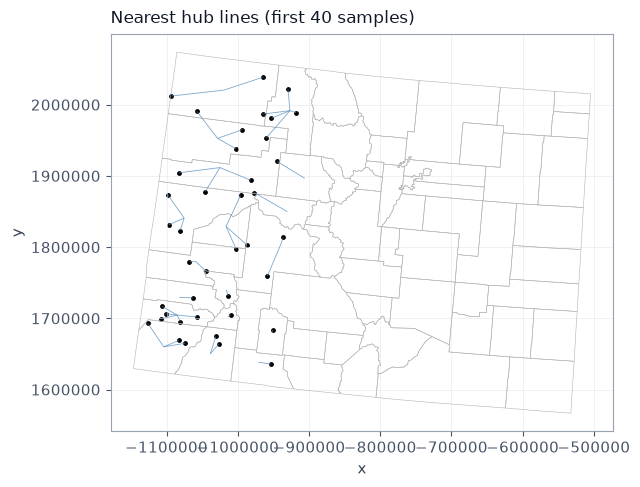

In [8]:
# Connect the first 40 samples to their nearest county hub as lines and as point distances.
hub_lines = distance_to_nearest_hub_lines(
    samples.head(40),  # origin samples
    hub_points,  # hub points (one per county)
    hub_field="COUNTY",  # attribute that names each hub
    unit="kilometers",  # report HubDist in kilometres
)
hub_pts = distance_to_nearest_hub_points(
    samples.head(40),  # same origin samples
    hub_points,  # same hub set
    hub_field="COUNTY",  # hub name field
    unit="kilometers",  # distance units
)
display(hub_pts[["ID", "COUNTY", "HubName", "HubDist"]].head())  # preview hub assignments

# Map: county boundaries, hub connector lines, and sample points.
fig, ax = plt.subplots(figsize=(7, 5))  # create the map figure
co_counties.boundary.plot(ax=ax, color="0.7", linewidth=0.4)  # county outlines
hub_lines.plot(ax=ax, color="steelblue", linewidth=0.6, alpha=0.7)  # sample-to-hub lines
samples.head(40).plot(ax=ax, color="black", markersize=6)  # sample points
style_axes(ax, "Nearest hub lines (first 40 samples)")  # title and axis styling
fig.tight_layout()  # reduce unused whitespace
plt.show()  # render the map


#### Join by lines (hub lines)

`join_by_lines()` draws lines between hubs and spokes that share the same ID. County polygons act as hubs and samples as spokes, matched on county name.



In [9]:
# Draw hub-spoke lines between counties and samples that share the same COUNTY value.
matched = join_by_lines(
    co_counties,  # hub polygons (county seats use representative points internally)
    samples,  # spoke points
    hub_field="COUNTY",  # join key on hubs
    spoke_field="COUNTY",  # join key on spokes
    hub_fields=["COUNTY"],  # hub attributes to keep
    spoke_fields=["ID", "SOC"],  # spoke attributes to keep
)
print(f"Connector lines: {len(matched)}")  # number of hub-spoke lines created
display(matched[["COUNTY", "ID", "SOC"]].head())  # preview matched attributes


Connector lines: 136


,COUNTY,ID,SOC
0,Moffat County,1,6.439
1,Montezuma County,2,2.821
2,Mesa County,3,2.760
3,Mesa County,4,10.535
4,Garfield County,5,5.528


#### Shortest line between features

For each sample, draw the shortest line to the nearest county polygon (up to one neighbour within 150 km).



,ID,COUNTY_1,COUNTY_2,distance
0,1,Moffat County,Moffat County,0.0
1,2,Montezuma County,Montezuma County,0.0
2,3,Mesa County,Mesa County,0.0
3,4,Mesa County,Mesa County,0.0
4,5,Garfield County,Garfield County,0.0


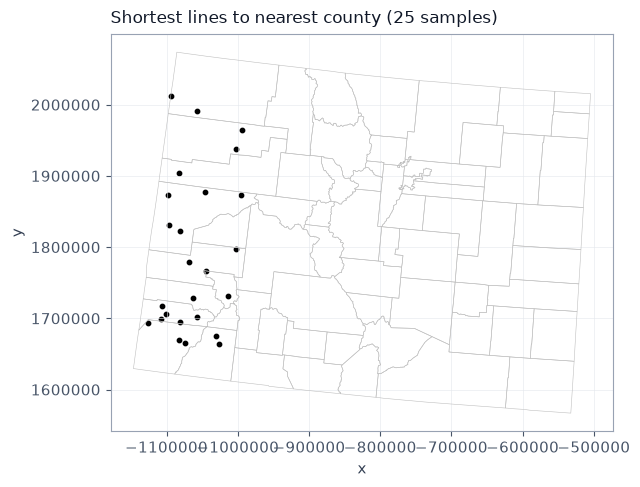

In [10]:
# For each of 25 samples, draw the shortest line to the nearest county polygon.
shortest = shortest_line_between_features(
    samples.head(25),  # origin samples
    co_counties,  # destination polygons
    method="nearest_point",  # snap to the nearest point on the polygon boundary
    neighbors=1,  # keep only the single nearest county
    max_distance=150_000,  # ignore matches farther than 150 km (layer units: metres)
)
display(shortest[["ID", "COUNTY_1", "COUNTY_2", "distance"]].head())  # preview distances

# Map shortest connectors against county boundaries and sample points.
fig, ax = plt.subplots(figsize=(7, 5))  # create the map figure
co_counties.boundary.plot(ax=ax, color="0.75", linewidth=0.4)  # county outlines
shortest.plot(ax=ax, color="crimson", linewidth=0.8)  # shortest-line connectors
samples.head(25).plot(ax=ax, color="black", markersize=10)  # sample points
style_axes(ax, "Shortest lines to nearest county (25 samples)")  # title and axis styling
fig.tight_layout()  # reduce unused whitespace
plt.show()  # render the map


### Clustering and spatial pattern

Group features in space (and time) or test whether points are clustered or dispersed.


#### DBSCAN clustering

DBSCAN groups dense clusters of points. `eps` is in layer units (metres here). Noise points get a null cluster id.



CLUSTER_ID
1    136
Name: count, dtype: int64


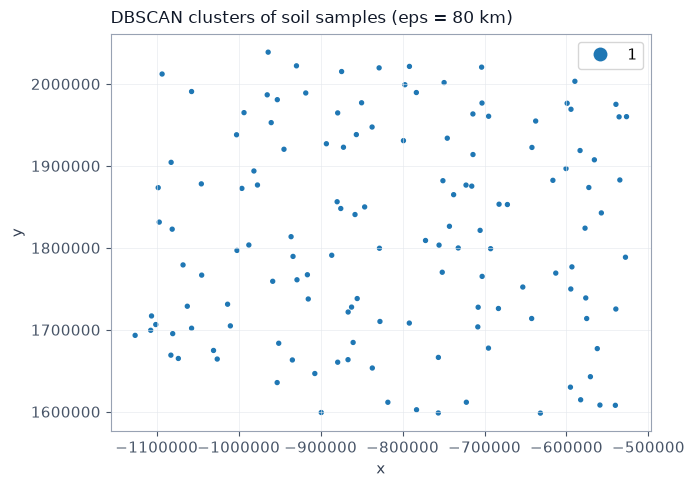

In [11]:
# Cluster soil samples with DBSCAN (min 4 points, 80 km neighbourhood radius).
dbscan = dbscan_clustering(samples, min_size=4, eps=80_000)  # eps in layer units (metres)
print(dbscan["CLUSTER_ID"].value_counts(dropna=False).head())  # cluster sizes (NaN = noise)

# Map clusters colored by CLUSTER_ID.
fig, ax = plt.subplots(figsize=(7, 5))  # create the map figure
dbscan.plot(column="CLUSTER_ID", categorical=True, legend=True, ax=ax, markersize=8)  # color by cluster id
style_axes(ax, "DBSCAN clusters of soil samples (eps = 80 km)")  # title and axis styling
fig.tight_layout()  # reduce unused whitespace
plt.show()  # render the map


#### K-means clustering

K-means partitions feature centroids into a fixed number of clusters. We use five clusters across Colorado samples.



Clusters found: 5


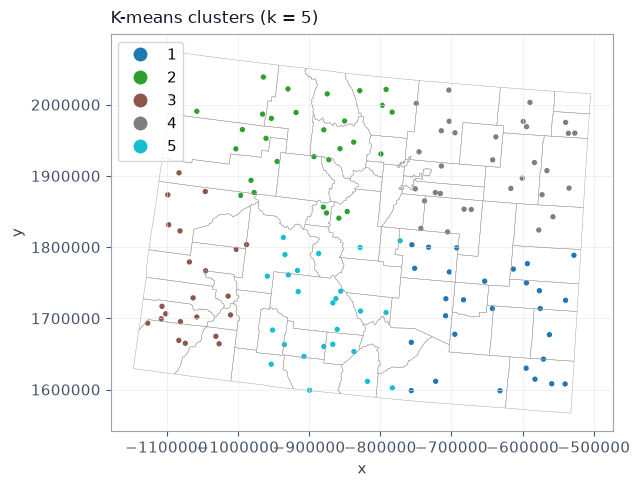

In [12]:
# Partition sample centroids into five K-means clusters (k-means++ seeding).
kmeans = kmeans_clustering(samples, n_clusters=5, method="kmeans++", random_state=42)  # five spatial clusters
print(f"Clusters found: {kmeans.attrs['num_clusters']}")  # confirm k from attrs

# Map K-means labels over Colorado county boundaries.
fig, ax = plt.subplots(figsize=(7, 5))  # create the map figure
kmeans.plot(column="CLUSTER_ID", categorical=True, legend=True, ax=ax, markersize=8)  # color by cluster id
co_counties.boundary.plot(ax=ax, color="0.6", linewidth=0.3)  # county context
style_axes(ax, "K-means clusters (k = 5)")  # title and axis styling
fig.tight_layout()  # reduce unused whitespace
plt.show()  # render the map


#### ST-DBSCAN clustering

ST-DBSCAN adds a temporal threshold: points must be close in space and in time. The `collected` field was derived from sample ID for this demo.



In [13]:
# Space-time DBSCAN: points must be close in space (80 km) and time (30 days).
st_clusters = stdbscan_clustering(
    samples,  # points with a synthetic collected timestamp
    "collected",  # datetime column for the temporal threshold
    min_size=4,  # minimum points to form a cluster
    eps=80_000,  # spatial neighbourhood radius in metres
    eps2=30,  # temporal neighbourhood in time_unit
    time_unit="days",  # interpret eps2 as days
)
print(st_clusters["CLUSTER_ID"].value_counts(dropna=False).head())  # cluster sizes


CLUSTER_ID
1    136
Name: count, dtype: int64


#### Nearest neighbour analysis

Clark-Evans nearest-neighbour analysis compares the observed mean nearest-neighbour distance to the distance expected under complete spatial randomness.



In [14]:
# Clark-Evans nearest-neighbour analysis: observed vs expected mean NN distance.
nna = nearest_neighbour_analysis(samples)  # returns a one-row summary table
display(nna)  # show NN index and related statistics
print(
    f"NN index {nna['NN_INDEX'].iloc[0]:.2f} "  # observed / expected ratio
    f"(< 1 clustered, ~ 1 random, > 1 dispersed)"  # interpretation guide
)


,OBSERVED_MD,EXPECTED_MD,NN_INDEX,POINT_COUNT,Z_SCORE
0,24993.887304,22034.612267,1.134301,136,2.996265


NN index 1.13 (< 1 clustered, ~ 1 random, > 1 dispersed)


### Overlay and aggregation

Count, sum, or measure how features from one layer fall inside or across polygons of another.


#### Count points in polygon

Each Colorado county receives the number of soil samples that fall inside it. We also show a weighted count using `SOC` as the weight.



In [15]:
# Count soil samples inside each Colorado county; also sum SOC as a weighted count.
counted = count_points_in_polygon(co_counties, samples, count_field="N_SAMPLES")  # raw counts
weighted = count_points_in_polygon(
    co_counties, samples, weight_field="SOC", count_field="SOC_SUM"
)  # sum of SOC per county
display(counted[["COUNTY", "N_SAMPLES"]].sort_values("N_SAMPLES", ascending=False).head())  # top counties by count
display(weighted[["COUNTY", "SOC_SUM"]].sort_values("SOC_SUM", ascending=False).head())  # top counties by SOC sum


,COUNTY,N_SAMPLES
10,El Paso County,6
52,Saguache County,6
32,Gunnison County,5
26,Dolores County,5
34,Mesa County,5


,COUNTY,SOC_SUM
32,Gunnison County,65.663
10,El Paso County,54.447
6,Rio Grande County,51.607
26,Dolores County,49.535
56,Larimer County,43.750


#### Overlap analysis

Overlap analysis measures how much of each input polygon is covered by overlay layers. Yellowstone is compared to Wyoming and Montana state polygons.



In [16]:
# Measure how much of Yellowstone is covered by Wyoming and Montana state polygons.
overlaps = overlap_analysis(park, [wyoming, montana])  # area and percent overlap per overlay
area_cols = [c for c in overlaps.columns if c.endswith("_area")]  # overlap area columns
pct_cols = [c for c in overlaps.columns if c.endswith("_pc")]  # overlap percent columns
display(overlaps[["PARKNAME", *area_cols, *pct_cols]])  # park name plus overlap metrics


,PARKNAME,layer_1_area,layer_2_area,layer_1_pc,layer_2_pc
0,Yellowstone,8.115999e+09,6.366662e+08,91.181987,7.152846


#### Sum line lengths

Each polygon receives the total length and count of street segments that intersect it. Onondaga streets are summed inside New York counties (values are in projection metres).



In [17]:
# Sum street centerline length and segment count inside each New York county.
line_totals = sum_line_lengths(ny_counties, streets)  # LENGTH (m) and COUNT per county
display(
    line_totals[["COUNTY", "LENGTH", "COUNT"]]
    .sort_values("LENGTH", ascending=False)
    .head(8)  # counties with the most street length
)
# Highlight Onondaga County (the street layer's home county) if present.
onondaga = line_totals.loc[line_totals["COUNTY"].str.contains("Onondaga", na=False)]
if len(onondaga):
    row = onondaga.iloc[0]  # first matching Onondaga row
    print(f"Onondaga: {row['COUNT']} segments, {row['LENGTH']:,.0f} m of centerline")


/home/zia207/Github/GeoLattice/src/vector/geoprocessing_vector_data.py:1088: UserWarning: Reprojecting the lines layer to the input CRS.
  return _align_crs_impl(data, other, other_name)


,COUNTY,LENGTH,COUNT
29,Onondaga County,433615.191116,999
44,Cortland County,28.321451,1
30,Madison County,11.087071,1
3,Franklin County,0.000000,0
4,Saint Lawrence County,0.000000,0
5,Saint Lawrence County,0.000000,0
6,Saint Lawrence County,0.000000,0
7,Essex County,0.000000,0


Onondaga: 999 segments, 433,615 m of centerline


### Geometry summary

Derive representative locations or elevation change from feature geometry.


#### Mean coordinates

The mean coordinate is the center of mass of feature centroids. Weighting by `SOC` shifts the center toward high-carbon samples.



In [18]:
# Compute unweighted, SOC-weighted, and per-county mean coordinates of the samples.
overall = mean_coordinates(samples)  # center of mass of all sample centroids
weighted_center = mean_coordinates(samples, weight_field="SOC")  # SOC-weighted center
by_county_center = mean_coordinates(samples, uid_field="COUNTY")  # one center per county
print(f"Unweighted center: ({overall.geometry.iloc[0].x:.0f}, {overall.geometry.iloc[0].y:.0f})")  # print unweighted XY
print(
    f"SOC-weighted center: ({weighted_center.geometry.iloc[0].x:.0f}, "
    f"{weighted_center.geometry.iloc[0].y:.0f})"
)
display(by_county_center.head())  # preview per-county centers


Unweighted center: (-813676, 1815127)
SOC-weighted center: (-855545, 1809304)


,COUNTY,geometry
0,Moffat County,POINT (-1020022.965 2007078.122)
1,Montezuma County,POINT (-1094231.927 1675741.423)
2,Mesa County,POINT (-1063572.818 1855633.158)
3,Garfield County,POINT (-996397.922 1898757.5)
4,Dolores County,POINT (-1090559.234 1703961.06)


#### Climb along line

`climb_along_line()` needs Z values on line vertices. The Onondaga streets are 2D, so this example builds a short 3D profile along the longest road segment by assigning a synthetic elevation to each vertex.



In [19]:
# Build a synthetic 3D profile on the longest street so climb_along_line has Z values.
road = streets.loc[[streets.geometry.length.idxmax()]].copy()  # longest street segment
coords = list(road.geometry.iloc[0].coords)  # 2D vertex list
z_profile = np.linspace(200, 260, len(coords))  # synthetic elevation ramp (m)
road_3d = road.copy()  # copy attributes onto the 3D version
road_3d["geometry"] = [
    LineString([(x, y, z) for (x, y), z in zip(coords, z_profile)])  # attach Z to each vertex
]

climbed = climb_along_line(road_3d)  # climb, descent, min/max elevation along the line
display(climbed[["CompleteSt", "climb", "descent", "minelev", "maxelev"]])  # climb metrics for the road
print(f"Layer total climb: {climbed.attrs['total_climb']:.1f} m")  # layer-level climb total


,CompleteSt,climb,descent,minelev,maxelev
0,North Road,60.0,0.0,200.0,260.0


Layer total climb: 60.0 m


## Part 2: Attribute manipulation 

Vector attribute manipulation involves working with the attribute data associated with geographic features in vector datasets. This process allows you to modify, aggregate, transform, and analyze the non-spatial information linked to each feature

This section follows the R attribute-manipulation tutorial. District rice production, upazila boundaries, and poverty percentages live under:

* `Data/00_shared/vector_data/Bangladesh/bd_district_rice_production_2018_2019_BTM.shp`
* `Data/00_shared/vector_data/Bangladesh/Shapefiles/bd_upzila_BTM.shp`
* `Data/00_shared/tabular_data/bd_poverty.csv` (also copied under `Data/00_shared/vector_data/Bangladesh/`)

The rice layer is in Bangladesh Transverse Mercator (BTM) metres.


In [20]:
# Load Bangladesh rice districts, upazila polygons, and the poverty CSV for Part 2.
rice_raw = read_layer("bd_district_rice_production_2018_2019_BTM.shp", base=BD)  # rice by district
upazilas_raw = read_layer("Shapefiles/bd_upzila_BTM.shp", base=BD)  # upazila polygons
poverty = pd.read_csv(TABULAR / "bd_poverty.csv")  # poverty percent by ADM3_PCODE

print(f"Rice districts: {len(rice_raw)}")  # district feature count
print(f"Upazilas: {len(upazilas_raw)}")  # upazila feature count
print(f"Poverty rows: {len(poverty)}")  # poverty table row count
display(rice_raw[["ADM1_EN", "ADM2_EN", "YEAR", "Aus", "Aman", "Boro"]].head())  # preview rice attributes
display(poverty.head())  # preview poverty table


Rice districts: 64
Upazilas: 544
Poverty rows: 544


,ADM1_EN,ADM2_EN,YEAR,Aus,Aman,Boro
0,Chittagong,Bandarban,2018-2019,23672,26210,24253
1,Barisal,Barguna,2018-2019,11650,116802,256997
2,Barisal,Barisal,2018-2019,38239,208723,195101
3,Barisal,Bhola,2018-2019,172102,423522,161003
4,Rajshahi,Bogra,2018-2019,57385,467997,709612


,ADM3_PCODE,POVERTY_PERCENT
0,BD400108,35.9
1,BD400114,50.0
2,BD400134,36.4
3,BD201358,42.5
4,BD400156,46.1


### Rename attributes

Division and district names are stored as `ADM1_EN` and `ADM2_EN`. Rename them to `DIV_Name` and `DIST_Name`, then map Aman production.


,DIV_Name,DIST_Name,YEAR,Aus,Aman,Boro
0,Chittagong,Bandarban,2018-2019,23672,26210,24253
1,Barisal,Barguna,2018-2019,11650,116802,256997
2,Barisal,Barisal,2018-2019,38239,208723,195101
3,Barisal,Bhola,2018-2019,172102,423522,161003
4,Rajshahi,Bogra,2018-2019,57385,467997,709612


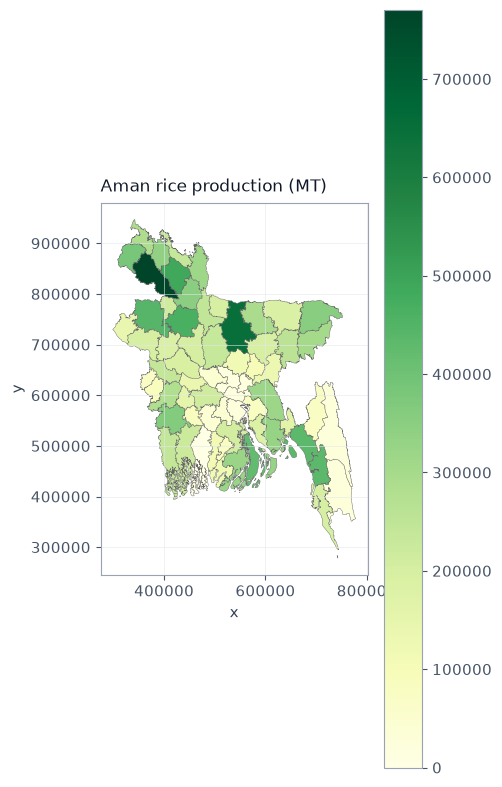

In [21]:
# Rename ADM name fields to clearer division/district labels.
rice = rename_fields(rice_raw, {"ADM1_EN": "DIV_Name", "ADM2_EN": "DIST_Name"})  # clearer division/district names
display(rice[["DIV_Name", "DIST_Name", "YEAR", "Aus", "Aman", "Boro"]].head())  # preview renamed fields

# Choropleth of Aman rice production by district.
fig, ax = plt.subplots(figsize=(5, 8))  # tall figure for Bangladesh
rice.plot(column="Aman", cmap="YlGn", legend=True, ax=ax, edgecolor="0.4", linewidth=0.3)  # Aman choropleth
style_axes(ax, "Aman rice production (MT)")  # title and axis styling
fig.tight_layout()  # reduce unused whitespace
plt.show()  # render the map


### Drop geometry

`drop_geometry()` keeps only the attribute table. That is useful when geometries are not needed for a table summary.


In [22]:
# Drop geometries to keep a plain attribute table (useful for non-spatial joins).
rice_table = drop_geometry(rice)  # returns a pandas DataFrame
print(type(rice_table))  # confirm DataFrame type
print(list(rice_table.columns))  # list remaining columns
display(rice_table[["DIST_Name", "DIV_Name", "Aus", "Aman", "Boro"]].head())  # preview attribute-only table


<class 'pandas.DataFrame'>
['Shape_Leng', 'Shape_Area', 'DIST_Name', 'ADM2_PCODE', 'ADM2_REF', 'ADM2ALT1EN', 'ADM2ALT2EN', 'DIV_Name', 'ADM1_PCODE', 'ADM0_EN', 'ADM0_PCODE', 'date', 'validOn', 'ValidTo', 'DISTRICT_I', 'YEAR', 'Aus', 'Aman', 'Boro']


,DIST_Name,DIV_Name,Aus,Aman,Boro
0,Bandarban,Chittagong,23672,26210,24253
1,Barguna,Barisal,11650,116802,256997
2,Barisal,Barisal,38239,208723,195101
3,Bhola,Barisal,172102,423522,161003
4,Bogra,Rajshahi,57385,467997,709612


### Filtering and selecting

Keep a subset of columns, then filter districts in the Rangpur and Rajshahi divisions. Also keep districts whose Boro production is below the national mean.


Northern districts: 16


,DIST_Name,DIV_Name,Aman,Boro
0,Bogra,Rajshahi,467997,709612
1,Dinajpur,Rangpur,770155,681567
2,Gaibandha,Rangpur,349760,479310
3,Joypurhat,Rajshahi,218127,290082
4,Kurigram,Rangpur,314620,477747


Mean Boro: 305,572 MT
Districts below mean Boro: 42


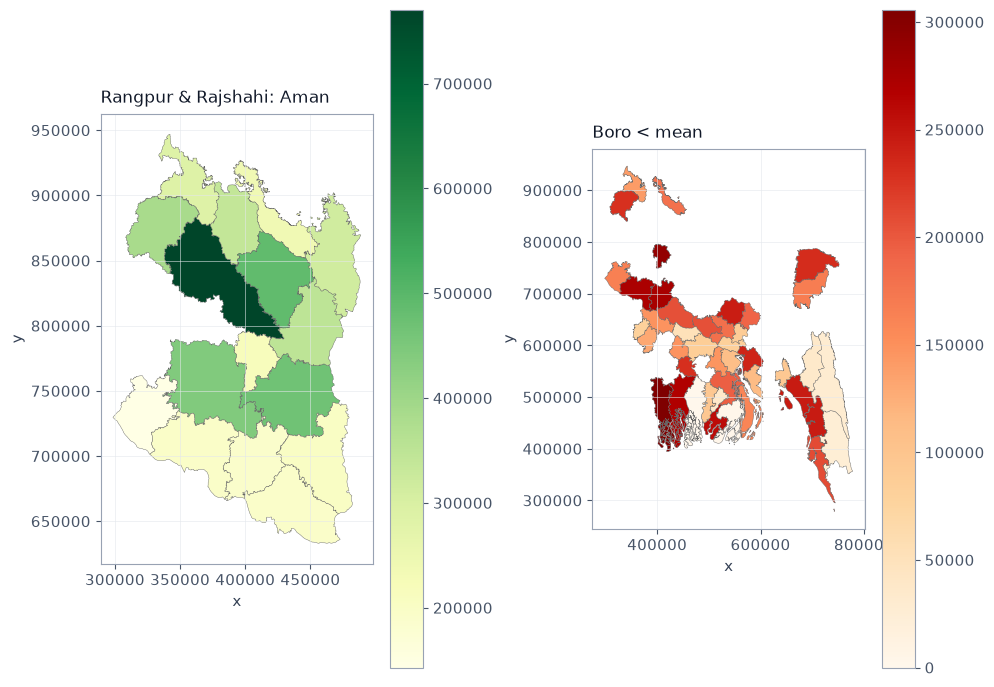

In [23]:
# Keep a compact column set, then filter to northern divisions and below-mean Boro districts.
rice_subset = select_fields(rice, ["DIST_Name", "DIV_Name", "YEAR", "Aus", "Aman", "Boro"])  # keep key columns
north = filter_features(rice_subset, "DIV_Name in ('Rangpur', 'Rajshahi')")  # northern divisions
print(f"Northern districts: {len(north)}")  # filtered row count
display(north[["DIST_Name", "DIV_Name", "Aman", "Boro"]].head())  # preview northern subset

mean_boro = float(rice["Boro"].mean())  # national mean Boro production (MT)
below_mean = filter_features(rice, f"Boro < {mean_boro}")  # districts below that mean
print(f"Mean Boro: {mean_boro:,.0f} MT")  # national mean
print(f"Districts below mean Boro: {len(below_mean)}")  # below-mean count

# Side-by-side maps: northern Aman vs below-mean Boro.
fig, axes = plt.subplots(1, 2, figsize=(10, 7))  # side-by-side maps
north.plot(column="Aman", cmap="YlGn", legend=True, ax=axes[0], edgecolor="0.4", linewidth=0.3)  # northern Aman
style_axes(axes[0], "Rangpur & Rajshahi: Aman")  # left panel title
below_mean.plot(column="Boro", cmap="OrRd", legend=True, ax=axes[1], edgecolor="0.4", linewidth=0.3)  # below-mean Boro
style_axes(axes[1], "Boro < mean")  # right panel title
fig.tight_layout()  # reduce unused whitespace
plt.show()  # render both maps


### Attribute aggregation

Sum Boro production by division. With `keep_geometry=True`, districts that share a division are dissolved into one polygon (same idea as `dplyr::summarise` on an `sf` object).


,DIV_Name,Boro,Aman,Aus
2,Rajshahi,3353049,2057113,572286
4,Dhaka,3185208,1206078,85977
5,Rangpur,3147449,3173651,137801
7,Mymensingh,2652092,1388280,56370
3,Khulna,2455726,1752203,398306
0,Chittagong,2435375,1959803,571912
6,Sylhet,1580734,1104120,467006
1,Barisal,746975,1256134,363258


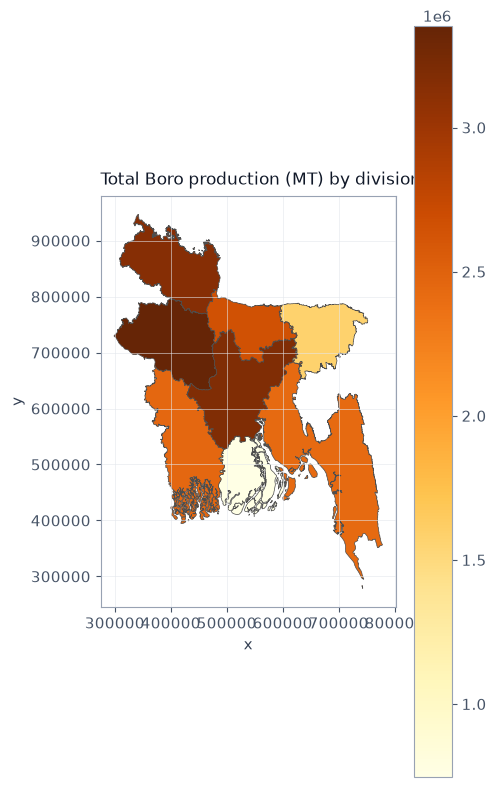

In [24]:
# Sum Aus/Aman/Boro production by division (dissolves district geometries).
by_div = aggregate_attributes(
    rice,  # district-level rice layer
    by="DIV_Name",  # group / dissolve key
    aggregations={"Boro": "sum", "Aman": "sum", "Aus": "sum"},  # sum each season
)
display(by_div[["DIV_Name", "Boro", "Aman", "Aus"]].sort_values("Boro", ascending=False))  # divisions by Boro

# Choropleth of total Boro by division.
fig, ax = plt.subplots(figsize=(5, 8))  # tall figure for Bangladesh
by_div.plot(column="Boro", cmap="YlOrBr", legend=True, ax=ax, edgecolor="0.3", linewidth=0.5)  # Boro by division
style_axes(ax, "Total Boro production (MT) by division")  # title and axis styling
fig.tight_layout()  # reduce unused whitespace
plt.show()  # render the map


### Sorting

Order districts by division name, then by Boro production descending.


In [25]:
# Sort districts by division name ascending, then Boro production descending.
ordered = sort_features(rice_subset, ["DIV_Name", "Boro"], ascending=[True, False])  # division then Boro desc
display(ordered[["DIV_Name", "DIST_Name", "Boro"]].head(10))  # top of the sorted table


,DIV_Name,DIST_Name,Boro
0,Barisal,Barguna,256997
1,Barisal,Barisal,195101
2,Barisal,Bhola,161003
3,Barisal,Pirojpur,95623
4,Barisal,Jhalokati,35488
5,Barisal,Patuakhali,2763
6,Chittagong,Comilla,661982
7,Chittagong,Brahamanbaria,471298
8,Chittagong,Noakhali,312046
9,Chittagong,Chittagong,244972


### Attribute joining

Join upazila-level poverty percentages onto the upazila polygons with the shared `ADM3_PCODE` key, then map poverty.


Joined upazilas: 544


,DIV_Name,DIST_Name,UPZ_Name,POVERTY_PERCENT
0,Khulna,Jessore,Abhaynagar,36.0
1,Dhaka,Dhaka,Adabor,12.5
2,Rajshahi,Bogra,Adamdighi,13.1
3,Rangpur,Lalmonirhat,Aditmari,36.0
4,Barisal,Barisal,Agailjhara,51.1


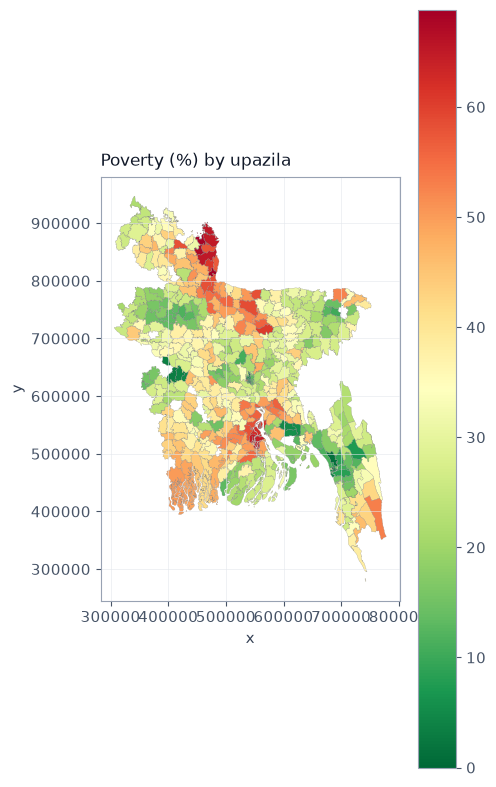

In [26]:
# Join upazila polygons to the poverty CSV on the shared ADM3_PCODE key.
upazilas = select_fields(
    upazilas_raw,  # full upazila layer
    ["ADM1_EN", "ADM2_EN", "ADM3_EN", "ADM3_PCODE"],  # keep name fields and join key
)
upazilas = rename_fields(
    upazilas,
    {"ADM1_EN": "DIV_Name", "ADM2_EN": "DIST_Name", "ADM3_EN": "UPZ_Name"},  # clearer labels
)
joined = join_attributes(upazilas, poverty, on="ADM3_PCODE", how="inner")  # keep matched rows
print(f"Joined upazilas: {len(joined)}")  # matched feature count
display(joined[["DIV_Name", "DIST_Name", "UPZ_Name", "POVERTY_PERCENT"]].head())  # preview joined attributes

# Choropleth of poverty percent by upazila.
fig, ax = plt.subplots(figsize=(5, 8))  # tall figure for Bangladesh
joined.plot(
    column="POVERTY_PERCENT",  # color by poverty percent
    cmap="RdYlGn_r",  # red = higher poverty
    legend=True,
    ax=ax,
    edgecolor="0.5",
    linewidth=0.15,
)
style_axes(ax, "Poverty (%) by upazila")  # title and axis styling
fig.tight_layout()  # reduce unused whitespace
plt.show()  # render the map


### Creating new attributes

Calculate total rice production as `Aus + Aman + Boro`.


,DIST_Name,DIV_Name,Aus,Aman,Boro,Total
0,Bandarban,Chittagong,23672,26210,24253,74135
1,Barguna,Barisal,11650,116802,256997,385449
2,Barisal,Barisal,38239,208723,195101,442063
3,Bhola,Barisal,172102,423522,161003,756627
4,Bogra,Rajshahi,57385,467997,709612,1234994


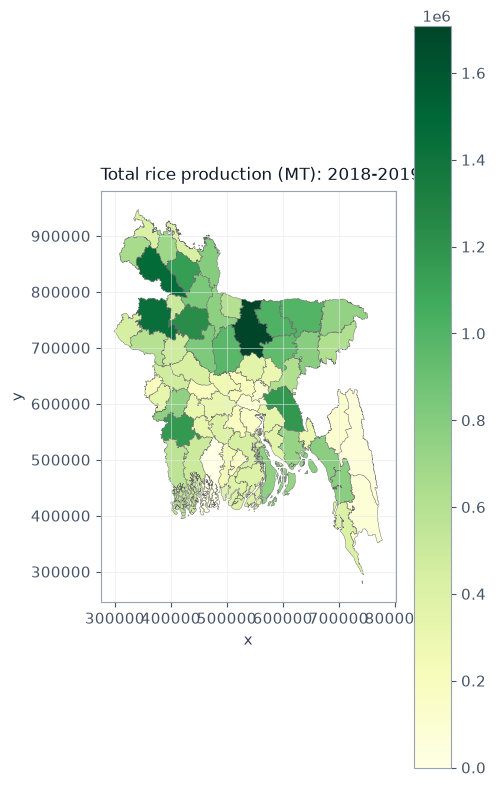

In [27]:
# Derive total rice production as Aus + Aman + Boro.
rice_total = calculate_fields(rice_subset, {"Total": "Aus + Aman + Boro"})  # sum of three seasons
display(rice_total[["DIST_Name", "DIV_Name", "Aus", "Aman", "Boro", "Total"]].head())  # preview totals

# Choropleth of total rice production.
fig, ax = plt.subplots(figsize=(5, 8))  # tall figure for Bangladesh
rice_total.plot(column="Total", cmap="YlGn", legend=True, ax=ax, edgecolor="0.4", linewidth=0.3)  # total choropleth
style_axes(ax, "Total rice production (MT): 2018-2019")  # title and axis styling
fig.tight_layout()  # reduce unused whitespace
plt.show()  # render the map


### String manipulation

Build uppercase district codes and three-letter abbreviations from district names.


In [28]:
# Build uppercase district names and three-letter codes from DIST_Name.
named = string_field(rice_total, "DIST_Name", "upper", output_field="DIST_UPPER")  # uppercase copy
named = string_field(
    named, "DIST_Name", "slice", start=0, stop=3, output_field="DIST_CODE"
)  # first three letters
display(named[["DIST_Name", "DIST_UPPER", "DIST_CODE", "Total"]].head())  # preview string fields


,DIST_Name,DIST_UPPER,DIST_CODE,Total
0,Bandarban,BANDARBAN,Ban,74135
1,Barguna,BARGUNA,Bar,385449
2,Barisal,BARISAL,Bar,442063
3,Bhola,BHOLA,Bho,756627
4,Bogra,BOGRA,Bog,1234994


### Conditional updating

Flag districts with below-mean Boro production, and scale Boro by 10% for Rangpur districts.


In [29]:
# Flag districts with below/above-mean Boro, and scale Boro by 10% for Rangpur districts.
mean_boro = float(rice_total["Boro"].mean())  # mean Boro across districts
flagged = update_where(
    rice_total,
    f"Boro < {mean_boro}",  # rows below the mean
    {"status": "low"},  # set status label
)
flagged = update_where(flagged, f"Boro >= {mean_boro}", {"status": "ok"})  # label the rest
rangpur = update_where(
    flagged,
    "DIV_Name == 'Rangpur'",  # only Rangpur division
    {"Boro_adj": "Boro * 1.1"},  # 10% uplift expression
)
display(
    rangpur.loc[rangpur["DIV_Name"] == "Rangpur", ["DIST_Name", "Boro", "Boro_adj", "status"]].head()
)
print(flagged["status"].value_counts())  # count of low vs ok labels


,DIST_Name,Boro,Boro_adj,status
12,Dinajpur,681567,749723.7,ok
15,Gaibandha,479310,527241.0,ok
27,Kurigram,477747,525521.7,ok
30,Lalmonirhat,179177,197094.7,low
45,Nilphamari,355759,391334.9,ok


status
low    42
ok     22
Name: count, dtype: int64


### Attribute transformation

Apply a numeric transform to total production (log1p) for skewed distributions.


In [30]:
# Apply log1p to total production for a less skewed numeric view.
transformed = transform_field(
    rice_total,
    "Total",  # input field
    np.log1p,  # natural log of (1 + x)
    output_field="log_Total",  # new column name
)
display(transformed[["DIST_Name", "Total", "log_Total"]].head())  # preview log-transformed totals


,DIST_Name,Total,log_Total
0,Bandarban,74135,11.213657
1,Barguna,385449,12.862167
2,Barisal,442063,12.999210
3,Bhola,756627,13.536627
4,Bogra,1234994,14.026577


### Reshaping

Melt seasonal rice columns to long form, then pivot back to wide form.


In [31]:
# Melt seasonal rice columns to long form, then pivot back to wide form.
long = reshape_attributes(
    rice_subset,
    to="long",  # wide -> long
    id_vars=["DIST_Name", "DIV_Name"],  # identity columns to keep
    value_vars=["Aus", "Aman", "Boro"],  # season columns to melt
    var_name="season",  # melted variable name column
    value_name="production",  # melted value column
)
print(f"Long rows: {len(long)}")  # melted row count
display(long.head(6))  # preview long-form table

wide = reshape_attributes(
    long,
    to="wide",  # long -> wide
    index=["DIST_Name", "DIV_Name"],  # row identity
    columns="season",  # column labels from season
    values="production",  # cell values
)
display(wide[["DIST_Name", "DIV_Name", "Aus", "Aman", "Boro"]].head())  # preview pivoted wide table


Long rows: 192


,DIST_Name,DIV_Name,season,production,geometry
0,Bandarban,Chittagong,Aus,23672,"POLYGON ((745209.502 471361.066, 745307.503 ..."
1,Barguna,Barisal,Aus,11650,"MULTIPOLYGON (((487586.812 441541.773, 48748..."
2,Barisal,Barisal,Aus,38239,"MULTIPOLYGON (((556973.901 498540.391, 55697..."
3,Bhola,Barisal,Aus,172102,"MULTIPOLYGON (((579740.046 417082.537, 57947..."
4,Bogra,Rajshahi,Aus,57385,"POLYGON ((432388.977 778757.759, 432400.165 ..."
5,Brahamanbaria,Chittagong,Aus,20992,"POLYGON ((632854.555 684469.887, 632869.305 ..."


,DIST_Name,DIV_Name,Aus,Aman,Boro
0,Bagerhat,Khulna,0,0,0
1,Bandarban,Chittagong,23672,26210,24253
2,Barguna,Barisal,11650,116802,256997
3,Barisal,Barisal,38239,208723,195101
4,Bhola,Barisal,172102,423522,161003


## Summary

### Spatial / statistical analysis (USA)

#### Attribute statistics

| Tool | Function | Data used |
|---|---|---|
| Field statistics | `basic_statistics_for_fields` | `SOC` on soil samples |
| Unique values | `list_unique_values` | County names |
| Stats by category | `statistics_by_categories` | `SOC` by county |

#### Distance and proximity

| Tool | Function | Data used |
|---|---|---|
| Distance matrix | `distance_matrix` | Samples to county hub points |
| Hub distance | `distance_to_nearest_hub_*` | Samples to county points |
| Hub lines | `join_by_lines` | Counties matched to samples by name |
| Shortest line | `shortest_line_between_features` | Samples to counties |

#### Clustering and spatial pattern

| Tool | Function | Data used |
|---|---|---|
| DBSCAN | `dbscan_clustering` | Soil samples |
| K-means | `kmeans_clustering` | Soil samples |
| ST-DBSCAN | `stdbscan_clustering` | Samples with `collected` time |
| NNA | `nearest_neighbour_analysis` | Soil samples |

#### Overlay and aggregation

| Tool | Function | Data used |
|---|---|---|
| Point in polygon | `count_points_in_polygon` | Samples in Colorado counties |
| Overlap | `overlap_analysis` | Yellowstone vs WY/MT |
| Line lengths | `sum_line_lengths` | NY streets in NY counties |

#### Geometry summary

| Tool | Function | Data used |
|---|---|---|
| Mean coordinate | `mean_coordinates` | Weighted and grouped centers |
| Climb | `climb_along_line` | 3D profile on longest street segment |

### Attribute manipulation (Bangladesh)

| Task | Function | Data used |
|---|---|---|
| Rename | `rename_fields` | Rice districts (`ADM1_EN` / `ADM2_EN`) |
| Drop geometry | `drop_geometry` | Rice attribute table |
| Filter / select | `filter_features`, `select_fields` | Rangpur & Rajshahi; Boro &lt; mean |
| Aggregate | `aggregate_attributes` | Boro / Aman / Aus by division |
| Sort | `sort_features` | Districts by division and Boro |
| Join | `join_attributes` | Upazilas + `bd_poverty.csv` |
| Calculate | `calculate_fields` | `Total = Aus + Aman + Boro` |
| Strings | `string_field` | District name codes |
| Conditional update | `update_where` | Low-Boro flag; Rangpur adjustment |
| Transform | `transform_field` | `log1p(Total)` |
| Reshape | `reshape_attributes` | Seasonal rice wide <-> long |



Vector analysis in GeoLattice covers attribute statistics, proximity, clustering, overlays, and geometry summaries. Attribute tools provide the same filtering, joining, aggregation, and reshape steps shown in the R `sf` / `dplyr` tutorial, while keeping geometries on GeoDataFrames.

### Further reading

* [GeoLattice vector analysis source](../../../geolattice/spatial_analysis/vector_analysis.py)
* [R attribute manipulation notes](../../../R_Code/vector-attribute-manipulation-r.qmd)
* [QGIS Vector analysis algorithms](https://docs.qgis.org/latest/en/docs/user_manual/processing_algs/qgis/vectoranalysis.html)
* Tutorial data: `Data/00_shared/vector_data/USA`, `Data/00_shared/vector_data/Bangladesh`, `data/tabular_data`
